In [1]:
import pandas as pd
import numpy as np
import pyvrp

In [2]:
data_nodos=pd.read_excel(r'datos_ejemplo_esmax.xlsx')

#10 clientes
#una planta
#no es necesario que todos los nodos podean ventanas de tiempo

In [3]:
data_nodos.head(11)

,Nodo,Pedido,Apertura,Cierre
0,Planta Maipú,0,05:00:00,20:00:00
1,Curicó,6,NaN,NaN
2,Molina,20,NaN,NaN
3,Pichilemu,13,NaN,NaN
4,Chimbarongo,9,NaN,NaN
5,Melipilla,10,NaN,NaN
6,Calera de Tango,19,06:00:00,22:00:00
7,Puente Alto,9,06:30:00,21:30:00
8,San Bernardo,6,06:00:00,22:00:00
9,Recoleta,16,07:00:00,23:00:00


In [4]:
data_nodos["Apertura"].map(type).value_counts()


Apertura
<class 'datetime.time'>    6
<class 'float'>            5
Name: count, dtype: int64

In [5]:
data_nodos["Apertura"] = pd.to_datetime(data_nodos["Apertura"].astype(str), errors="coerce")
data_nodos["Cierre"] = pd.to_datetime(data_nodos["Cierre"].astype(str), errors="coerce")


data_nodos["Apertura"] = data_nodos["Apertura"].dt.hour * 60 + data_nodos["Apertura"].dt.minute
data_nodos["Cierre"] = data_nodos["Cierre"].dt.hour * 60 + data_nodos["Cierre"].dt.minute

data_nodos["Apertura"] = data_nodos["Apertura"].fillna(-1).astype(int)
data_nodos["Cierre"] = data_nodos["Cierre"].fillna(-1).astype(int)


C:\Users\javie\AppData\Local\Temp\ipykernel_15648\2220081520.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data_nodos["Apertura"] = pd.to_datetime(data_nodos["Apertura"].astype(str), errors="coerce")
C:\Users\javie\AppData\Local\Temp\ipykernel_15648\2220081520.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data_nodos["Cierre"] = pd.to_datetime(data_nodos["Cierre"].astype(str), errors="coerce")


In [6]:
data_nodos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Nodo      11 non-null     object
 1   Pedido    11 non-null     int64 
 2   Apertura  11 non-null     int32 
 3   Cierre    11 non-null     int32 
dtypes: int32(2), int64(1), object(1)
memory usage: 396.0+ bytes


In [7]:
data_nodos.head(11)

,Nodo,Pedido,Apertura,Cierre
0,Planta Maipú,0,300,1200
1,Curicó,6,-1,-1
2,Molina,20,-1,-1
3,Pichilemu,13,-1,-1
4,Chimbarongo,9,-1,-1
5,Melipilla,10,-1,-1
6,Calera de Tango,19,360,1320
7,Puente Alto,9,390,1290
8,San Bernardo,6,360,1320
9,Recoleta,16,420,1380


In [8]:
df_distancias=pd.read_excel(r'distancias_ejemplo_esmax.xlsx')
#distancias tomadas de google maps, de manera aproximada

In [9]:
df_distancias=df_distancias.iloc[:,1:]

In [10]:
matriz=df_distancias.to_numpy()
print(matriz)

[[  0 170 184 150 135  46  12  18   8  16   4]
 [170   0  16  92  35 145 156 164 160 183 171]
 [184  16   0 102  49 159 171 177 175 198 186]
 [150  92 102   0  97 109 142 157 148 166 153]
 [135  35  49  97   0 116 122 129 126 147 137]
 [ 46 145 159 109 116   0  43  59  47  60  50]
 [ 12 156 171 142 122  43   0  17   5  25  15]
 [ 18 164 177 157 129  59  17   0  12  18  17]
 [  8 160 175 148 126  47   5  12   0  18   9]
 [ 16 183 198 166 147  60  25  18  18   0  12]
 [  4 171 186 153 137  50  15  17   9  12   0]]


##### Creando el modelo

Se añaden los datos de la planta, los clientes, y las distancias entre todos los nodos.

In [11]:
modelo=pyvrp.Model()
modelo.add_depot(0,0, name='Planta Maipú', tw_early=int(data_nodos.iloc[0,2]),tw_late=int(data_nodos.iloc[0,3]))


In [12]:
for i in range(1,len(data_nodos['Nodo'])):
    if int(data_nodos.iloc[i,2])==-1 and int(data_nodos.iloc[i,3])==-1:
        modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]),name=str(data_nodos.iloc[i,0]))
    elif int(data_nodos.iloc[i,2])==-1 and int(data_nodos.iloc[i,3])!=-1:
        modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]), tw_late=int(data_nodos.iloc[i,3]),name=str(data_nodos.iloc[i,0]))
    elif int(data_nodos.iloc[i,2])!=-1 and int(data_nodos.iloc[i,3])==-1:
        modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]),tw_early=int(data_nodos.iloc[i,2]), name=str(data_nodos.iloc[i,0]))
    elif int(data_nodos.iloc[i,2])!=-1 and int(data_nodos.iloc[i,3])!=-1:
        modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]),tw_early=int(data_nodos.iloc[i,2]), tw_late=int(data_nodos.iloc[i,3]), name=str(data_nodos.iloc[i,0]))



In [13]:
for frm_idx, frm in enumerate(modelo.locations):
    for to_idx, to in enumerate(modelo.locations):
        modelo.add_edge(frm, to, distance=matriz[frm_idx][to_idx])

In [14]:
modelo.locations

También se añaden los datos de los vehículos. Estos son datos reales de vehículos extraídos de los datos compartidos desde esmax, siendo todos vehículos asociados a la Planta Maipú. Acá se identifican según el orden en que se añaden al modelo, siendo el primero 0, el segundo 1 y el tercero 2. Esto nos ayudará a comprender la solución final.

In [15]:
modelo.add_vehicle_type(capacity=int(20), num_available=int(5), start_depot=modelo.locations[0], end_depot=modelo.locations[0], tw_early=int(600), name='camion_1')
modelo.add_vehicle_type(capacity=int(35), num_available=int(1), start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_2')
modelo.add_vehicle_type(capacity=int(27), num_available=int(10), start_depot=modelo.locations[0], end_depot=modelo.locations[0],tw_early=int(320), name='camion_3')

##### La solución
Se obtiene la solución del modelo según el algoritmo. Se explica más abajo.


In [16]:
from pyvrp.stop import MaxRuntime
res = modelo.solve( stop = MaxRuntime (5) , seed = 3)

PyVRP v0.11.3

Solving an instance with:
    1 depot
    10 clients
    16 vehicles (3 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  32      832      760 |  55      729      681
     1000      2s |  42      809      760 |  63      762      731
     1500      3s |  48      811      760 |  30      790      731
     2000      3s |  60      809      760 |  53      662      616
     2500      4s |  29      815      760 |  61      658      616

Search terminated in 5.00s after 2989 iterations.
Best-found solution has cost 760.

Solution results
    # routes: 5
     # trips: 5
   # clients: 10
   objective: 760
    distance: 760
    duration: 0
# iterations: 2989
    run-time: 5.00 seconds



In [17]:
print(res)

Solution results
    # routes: 5
     # trips: 5
   # clients: 10
   objective: 760
    distance: 760
    duration: 0
# iterations: 2989
    run-time: 5.00 seconds

Routes
------
Route #1: 4 1 2
Route #2: 9 7
Route #3: 8 6
Route #4: 3 5
Route #5: 10



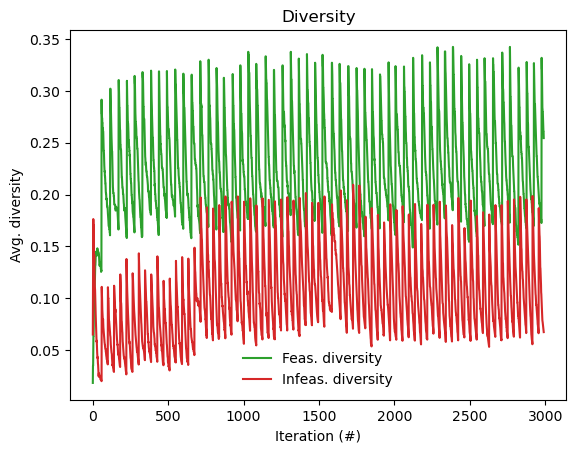

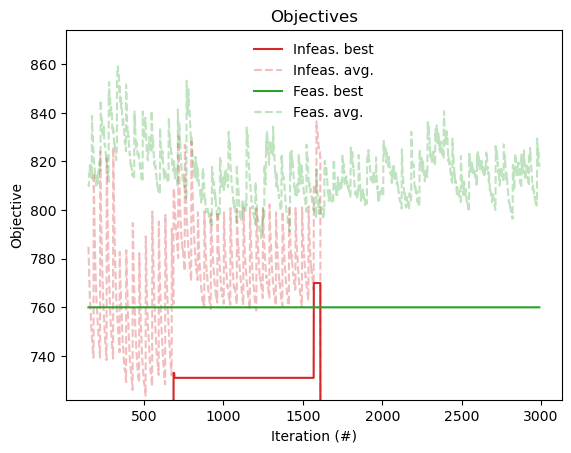

In [18]:
from pyvrp.plotting import plot_diversity, plot_objectives

plot_diversity(res)
plot_objectives(res)

In [19]:
best=res.best
rutas=best.routes()
num_rutas=best.num_routes()

In [20]:
for i in range(0,num_rutas):
    print(f' La ruta recorrida por el vehículo {rutas[i].vehicle_type()} son los clientes {rutas[i]}, y comienza a las {rutas[i].start_time()}')

 La ruta recorrida por el vehículo 1 son los clientes 4 1 2, y comienza a las 300
 La ruta recorrida por el vehículo 2 son los clientes 9 7, y comienza a las 420
 La ruta recorrida por el vehículo 2 son los clientes 8 6, y comienza a las 360
 La ruta recorrida por el vehículo 2 son los clientes 3 5, y comienza a las 320
 La ruta recorrida por el vehículo 2 son los clientes 10, y comienza a las 360
